In [1]:
import numpy as np
from PIL import Image, ImageDraw
from pathlib import Path

root = Path(r"C:\Users\t.asmus\Desktop\data\AnyVisLoc\Scene_10\Scene_10")

pp = root / "L10_0119.npz"

file = np.load(pp)


# Image.fromarray(file["image"])

In [5]:
file.files

['image',
 'image_relpath',
 'K',
 'dist',
 'uav_downsample',
 'image_size',
 'pose_c2w',
 'pose_w2c',
 'xyz',
 'euler_deg',
 'scene_id',
 'sample_id']

In [4]:
file["image_size"]

array([ 750, 1000], dtype=int32)

In [1]:
def coords_to_pixel(point: list[int|float]|tuple[int|float, int|float],  
                    map_resolution: list[float]|tuple[float, float], 
                    map_origin: list[float]|tuple[float, float]) -> tuple[int, int]:
    x_meters, y_meters = point
    
    x = int((x_meters - map_origin[0]) / map_resolution[0])
    y = int((y_meters - map_origin[1]) / map_resolution[1])

    return x, y


def correct_coord_after_map_resize(point: list[int|float]|tuple[int|float, int|float], 
                                   resize: int, 
                                   image_size: list[int]|tuple[int, int], 
                                   map_resolution: list[float]|tuple[float, float], 
                                   map_origin: list[float]|tuple[float, float]) -> tuple[int, int]:
    x_meters, y_meters = coords_to_pixel(point, map_resolution, map_origin)

    x = int((x_meters - map_origin[0]) / map_resolution[0])
    y = int((y_meters - map_origin[1]) / map_resolution[1]) 

    w, h = image_size

    scale_x = resize / w
    scale_y = resize / h

    x = int(x * scale_x)
    y = int(y * scale_y)

    return x, y

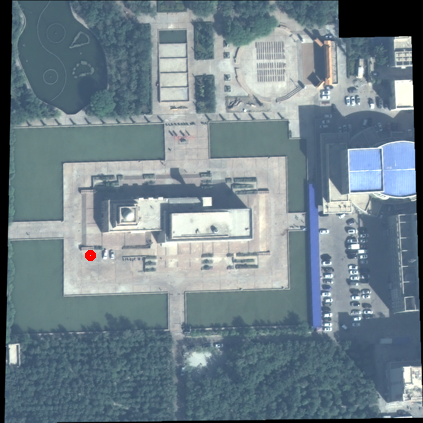

In [ ]:
import json 

SIZE = 423

with open(root / 'L10_reference.json', 'r') as f:
    ref_data = json.load(f)
satellite_info = ref_data['modes']['satellite']
map_resolution = satellite_info['map_resolution']  # [res_x, res_y] в метрах/пиксель
map_origin = satellite_info['map_origin_local']  # [origin_x, origin_y] в метрах

x_meters, y_meters, _ = file["xyz"]
point = (x_meters, y_meters)
r = 5
img = Image.open(root / "satellite_map.png")
w, h = img.size

x, y = correct_coord_after_map_resize(point, SIZE, (w, h), map_resolution, map_origin)

img = img.resize((SIZE, SIZE))

draw = ImageDraw.Draw(img)
bounding_box = [x-r, y-r, x+r, y+r]
draw.ellipse(bounding_box, fill='lightblue', outline='red', width=5)

img

In [6]:
satellite_info

{'map_path': 'satellite_map.png',
 'dsm_path': 'satellite_dsm.npy',
 'map_resolution': [0.25, 0.25],
 'dsm_resolution': [30.0, 30.0],
 'map_origin_local': [-3.753570556640625, 0.3298109769821167],
 'dsm_origin_local': [-35.474998474121094, -21.784000396728516],
 'map_size': [904, 918],
 'dsm_size': [9, 10],
 'map_field': 'satellite_map.png',
 'dsm_field': 'satellite_dsm.npy'}

In [2]:
from pathlib import Path
from datasets.AnyVisLoc import AnyVisLocDataset

root = Path(r"C:\Users\t.asmus\Desktop\data\AnyVisLoc\Scene_10\Scene_10")

satellite_resize = 1024
image_resize = 512
p = [root]

data = AnyVisLocDataset(p, satellite_resize, image_resize)

train = data.get_train_part()
test = data.get_test_part() 

point, sat, image = train[5]

print(point)
print(sat.shape)
print(image.shape)

L10_0006.npz
tensor([496.2080, 243.2298])
torch.Size([3, 1024, 1024])
torch.Size([3, 512, 512])


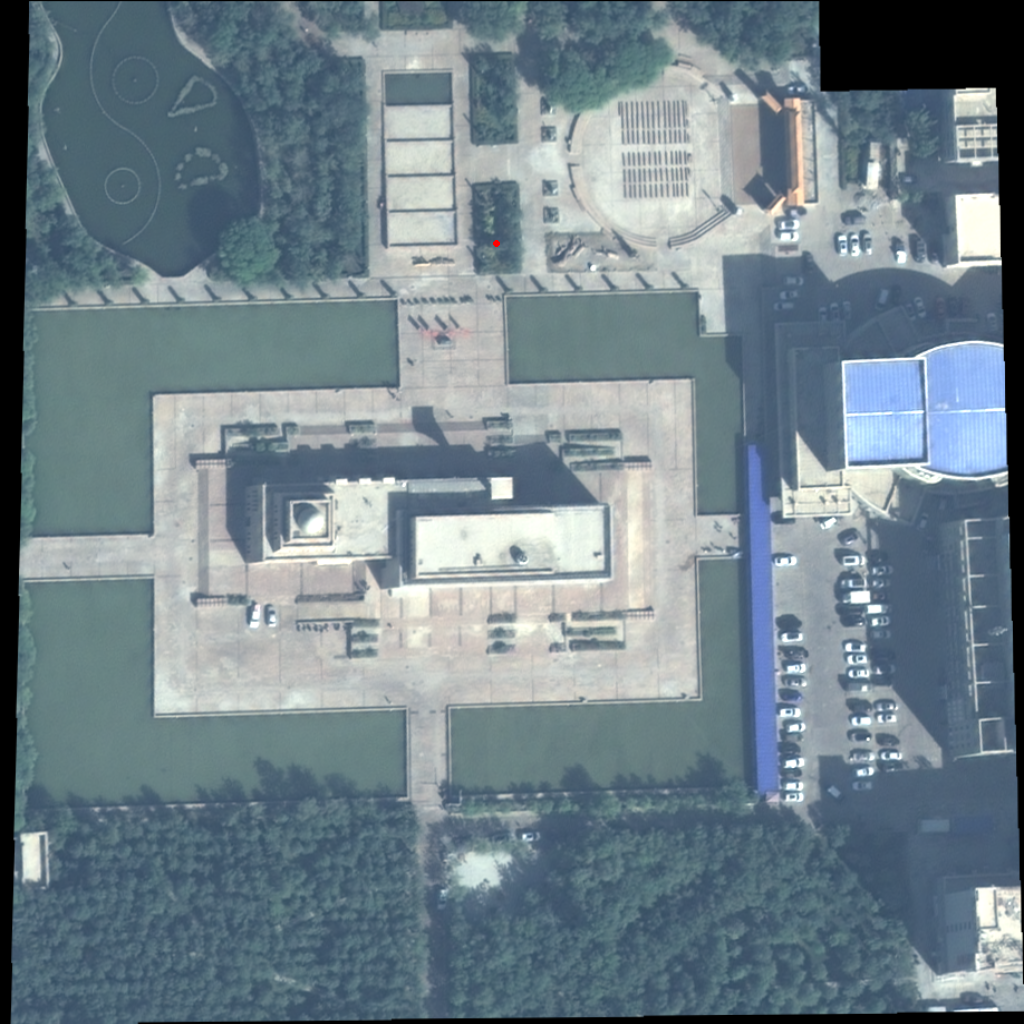

In [3]:
import numpy as np
from PIL import Image, ImageDraw

r = 3

sat = sat.permute(2, 1, 0).numpy()
image = image.permute(2, 1, 0).numpy()

sat = sat.astype(np.uint8)
image = image.astype(np.uint8)

point = point.numpy().astype(np.int32)
x ,y = point

# draw

sat = Image.fromarray(sat)
image = Image.fromarray(image)

for_edit_sat = sat.copy()

draw = ImageDraw.Draw(for_edit_sat)
bounding_box = [x-r, y-r, x+r, y+r]
draw.ellipse(bounding_box, fill='lightblue', outline='red', width=5)

for_edit_sat

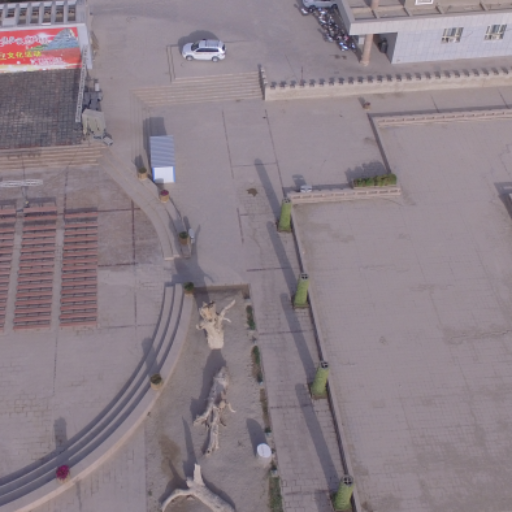

In [4]:
image

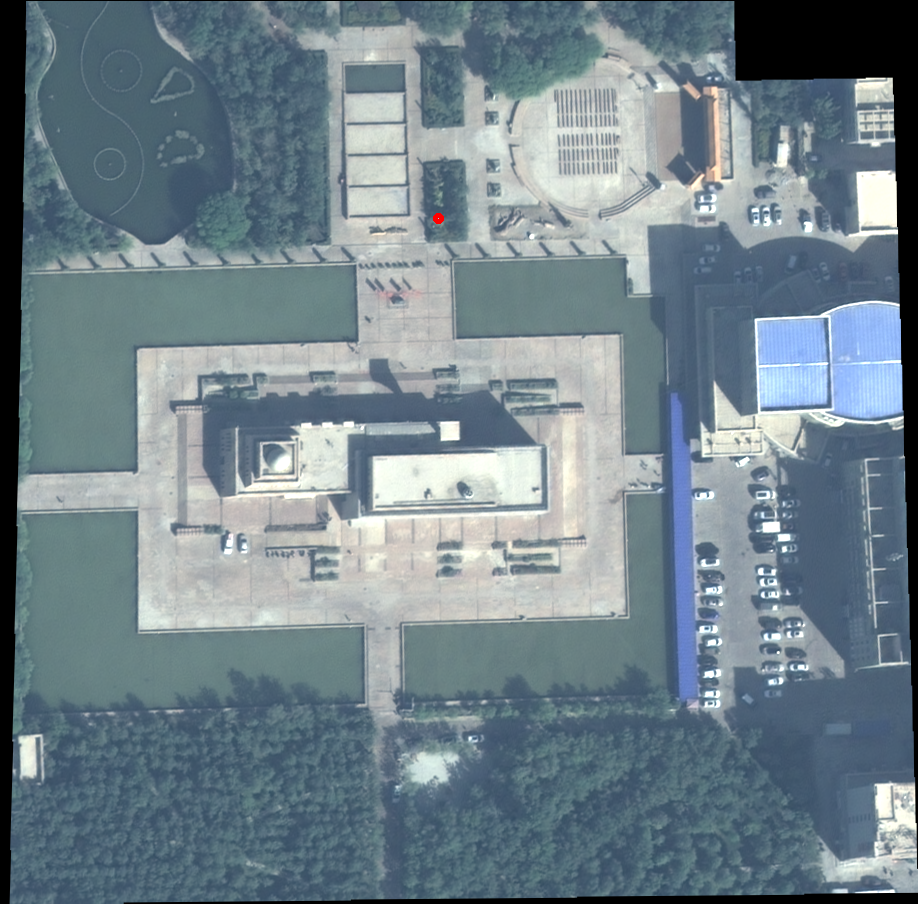

In [8]:
import json
import numpy as np
from PIL import Image, ImageDraw

with open(root / 'L10_reference.json', 'r') as f:
    ref_data = json.load(f)
satellite_info = ref_data['modes']['satellite']
map_resolution = satellite_info['map_resolution'] 
map_origin = satellite_info['map_origin_local'] 

pp = root / "L10_0006.npz"
file = np.load(pp)
x_meters, y_meters, _ = file["xyz"]
point = (x_meters, y_meters)
x, y = coords_to_pixel(point, map_resolution, map_origin)

org_sat = Image.open(root / "satellite_map.png")

r = 5
draw = ImageDraw.Draw(org_sat)
bounding_box = [x-r, y-r, x+r, y+r]
draw.ellipse(bounding_box, fill='lightblue', outline='red', width=5)

org_sat